In [ ]:
# 1. Mount Drive
from google.colab import drive
drive.mount('/content/drive')

# 2. Cài thư viện cần cho Tuần 2 (composite, augmentation, split)
!pip install -q tensorflow-datasets importlib_resources pillow numpy pandas scikit-learn

# 3. Xác nhận đường dẫn gốc dự án
import os
BASE = '/content/drive/MyDrive/flower-multilabel-project'
print("Project tồn tại:", os.path.exists(BASE))

# 4. Kiểm tra lại dữ liệu raw còn nguyên vẹn (đúng số lượng như đã thu thập Tuần 1)
classes = [
    'hoa_hong', 'hoa_huong_duong', 'hoa_cuc', 'hoa_tulip', 'hoa_bo_cong_anh',
    'hoa_sen', 'hoa_lan', 'hoa_mai', 'hoa_dao', 'hoa_oai_huong'
]

total = 0
print(f"\n{'Lớp':<20}{'Số ảnh'}")
for c in classes:
    folder = os.path.join(BASE, 'data/raw', c)
    n = len(os.listdir(folder)) if os.path.exists(folder) else 0
    total += n
    print(f"{c:<20}{n}")
print(f"\nTổng: {total} ảnh — cần khớp với 5015 đã ghi nhận Tuần 1")

# 5. Đảm bảo các thư mục Tuần 2 cần dùng đã có sẵn
week2_folders = [
    'data/composite/images',
    'data/augmented',
    'data/splits/train', 'data/splits/val', 'data/splits/test',
    'data/metadata',
]
for f in week2_folders:
    os.makedirs(os.path.join(BASE, f), exist_ok=True)
print("\n✅ Sẵn sàng bắt đầu Tuần 2")

Mounted at /content/drive
Project tồn tại: True

Lớp                 Số ảnh
hoa_hong            784
hoa_huong_duong     733
hoa_cuc             764
hoa_tulip           984
hoa_bo_cong_anh     1052
hoa_sen             137
hoa_lan             100
hoa_mai             159
hoa_dao             168
hoa_oai_huong       134

Tổng: 5015 ảnh — cần khớp với 5015 đã ghi nhận Tuần 1

✅ Sẵn sàng bắt đầu Tuần 2


In [ ]:
import json

classes = [
    'hoa_hong', 'hoa_huong_duong', 'hoa_cuc', 'hoa_tulip', 'hoa_bo_cong_anh',
    'hoa_sen', 'hoa_lan', 'hoa_mai', 'hoa_dao', 'hoa_oai_huong'
]

display_names = {
    'hoa_hong': 'Hoa Hồng',
    'hoa_huong_duong': 'Hoa Hướng Dương',
    'hoa_cuc': 'Hoa Cúc',
    'hoa_tulip': 'Hoa Tulip',
    'hoa_bo_cong_anh': 'Bồ Công Anh',
    'hoa_sen': 'Hoa Sen',
    'hoa_lan': 'Hoa Lan',
    'hoa_mai': 'Hoa Mai',
    'hoa_dao': 'Hoa Đào',
    'hoa_oai_huong': 'Oải Hương'
}

classes_meta = [
    {"index": i, "id": c, "name": display_names[c]}
    for i, c in enumerate(classes)
]

meta_path = os.path.join(BASE, 'data/metadata/classes.json')
with open(meta_path, 'w', encoding='utf-8') as f:
    json.dump(classes_meta, f, ensure_ascii=False, indent=2)

print("✅ Đã tạo classes.json với thứ tự cố định:")
for item in classes_meta:
    print(f"  {item['index']}: {item['id']} ({item['name']})")

✅ Đã tạo classes.json với thứ tự cố định:
  0: hoa_hong (Hoa Hồng)
  1: hoa_huong_duong (Hoa Hướng Dương)
  2: hoa_cuc (Hoa Cúc)
  3: hoa_tulip (Hoa Tulip)
  4: hoa_bo_cong_anh (Bồ Công Anh)
  5: hoa_sen (Hoa Sen)
  6: hoa_lan (Hoa Lan)
  7: hoa_mai (Hoa Mai)
  8: hoa_dao (Hoa Đào)
  9: hoa_oai_huong (Oải Hương)


In [ ]:
import random
from PIL import Image
import pandas as pd

random.seed(42)  # để tái lập kết quả

RAW_DIR = os.path.join(BASE, 'data/raw')
COMPOSITE_IMG_DIR = os.path.join(BASE, 'data/composite/images')
CANVAS_SIZE = (224, 224)  # khớp input size của model (mục 4 blueprint)

# Load danh sách ảnh có sẵn theo từng lớp
class_images = {}
for c in classes:
    folder = os.path.join(RAW_DIR, c)
    files = [f for f in os.listdir(folder) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    class_images[c] = files
    print(f"{c}: {len(files)} ảnh")

hoa_hong: 784 ảnh
hoa_huong_duong: 733 ảnh
hoa_cuc: 764 ảnh
hoa_tulip: 984 ảnh
hoa_bo_cong_anh: 1052 ảnh
hoa_sen: 137 ảnh
hoa_lan: 100 ảnh
hoa_mai: 159 ảnh
hoa_dao: 167 ảnh
hoa_oai_huong: 132 ảnh


Thử ghép: ['hoa_huong_duong', 'hoa_dao', 'hoa_oai_huong']


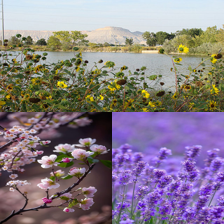

In [ ]:
def create_composite(selected_classes, class_images, raw_dir, canvas_size=(224,224)):
    """
    selected_classes: list các class id (1-3 phần tử) sẽ xuất hiện trong ảnh
    Trả về: ảnh PIL đã ghép
    """
    canvas = Image.new('RGB', canvas_size, (255, 255, 255))
    n = len(selected_classes)
    w, h = canvas_size

    if n == 1:
        regions = [(0, 0, w, h)]
    elif n == 2:
        regions = [(0, 0, w//2, h), (w//2, 0, w, h)]
    else:  # n == 3
        regions = [(0, 0, w, h//2), (0, h//2, w//2, h), (w//2, h//2, w, h)]

    for cls, (x1, y1, x2, y2) in zip(selected_classes, regions):
        img_file = random.choice(class_images[cls])
        img_path = os.path.join(raw_dir, cls, img_file)
        try:
            img = Image.open(img_path).convert('RGB')
        except Exception as e:
            print(f"Lỗi mở ảnh {img_path}: {e}")
            continue
        region_w, region_h = x2 - x1, y2 - y1
        img = img.resize((region_w, region_h))
        canvas.paste(img, (x1, y1))

    return canvas

# Thử tạo 1 ảnh mẫu để kiểm tra trước
sample_classes = random.sample(classes, k=random.randint(1,3))
print("Thử ghép:", sample_classes)
sample_img = create_composite(sample_classes, class_images, RAW_DIR)
sample_img.save('/content/sample_composite_test.jpg')
sample_img

In [ ]:
N_COMPOSITE = 3000  # số ảnh composite cần tạo — có thể chỉnh

records = []

for i in range(N_COMPOSITE):
    n_flowers = random.randint(1, 3)
    selected = random.sample(classes, k=n_flowers)  # không trùng lớp trong cùng 1 ảnh

    composite_img = create_composite(selected, class_images, RAW_DIR)

    filename = f"composite_{i:05d}.jpg"
    save_path = os.path.join(COMPOSITE_IMG_DIR, filename)
    composite_img.save(save_path, quality=90)

    # Tạo vector multi-hot đúng thứ tự classes.json
    label_row = {"filename": filename}
    for c in classes:
        label_row[c] = 1 if c in selected else 0
    records.append(label_row)

    if (i+1) % 500 == 0:
        print(f"Đã tạo {i+1}/{N_COMPOSITE} ảnh...")

# Lưu labels.csv
labels_df = pd.DataFrame(records)
labels_csv_path = os.path.join(BASE, 'data/composite/labels.csv')
labels_df.to_csv(labels_csv_path, index=False)

print(f"\n✅ Hoàn thành: {len(labels_df)} ảnh composite")
print(f"Đã lưu: {labels_csv_path}")
labels_df.head()

Đã tạo 500/3000 ảnh...
Đã tạo 1000/3000 ảnh...
Đã tạo 1500/3000 ảnh...
Đã tạo 2000/3000 ảnh...
Đã tạo 2500/3000 ảnh...
Lỗi mở ảnh /content/drive/MyDrive/flower-multilabel-project/data/raw/hoa_hong/hoa_hong_0043.jpg: [Errno 2] No such file or directory: '/content/drive/MyDrive/flower-multilabel-project/data/raw/hoa_hong/hoa_hong_0043.jpg'
Đã tạo 3000/3000 ảnh...

✅ Hoàn thành: 3000 ảnh composite
Đã lưu: /content/drive/MyDrive/flower-multilabel-project/data/composite/labels.csv


,filename,hoa_hong,hoa_huong_duong,hoa_cuc,hoa_tulip,hoa_bo_cong_anh,hoa_sen,hoa_lan,hoa_mai,hoa_dao,hoa_oai_huong
0,composite_00000.jpg,0,1,0,0,0,0,0,0,0,0
1,composite_00001.jpg,0,0,0,0,0,0,0,0,1,0
2,composite_00002.jpg,0,0,0,0,0,0,0,0,1,0
3,composite_00003.jpg,0,0,0,1,0,0,1,0,1,0
4,composite_00004.jpg,0,0,1,0,0,0,0,0,0,0


In [ ]:
print("Số lần mỗi lớp xuất hiện trong composite:")
print(labels_df[classes].sum().sort_values(ascending=False))

Số lần mỗi lớp xuất hiện trong composite:
hoa_huong_duong    646
hoa_lan            630
hoa_mai            629
hoa_tulip          605
hoa_oai_huong      603
hoa_cuc            602
hoa_bo_cong_anh    594
hoa_hong           579
hoa_sen            578
hoa_dao            573
dtype: int64


In [ ]:
# 1. Xác định (các) ảnh composite bị lỗi do dùng file đã xóa
# Vì ta không lưu lại file gốc dùng cho mỗi composite, cách an toàn nhất là
# quét lại toàn bộ thư mục composite, tìm ảnh có vùng "trắng thuần" bất thường
# (do PIL.new nền trắng khi paste lỗi bị bỏ qua)

import numpy as np

def has_suspicious_blank_region(img_path, canvas_size=(224,224)):
    img = np.array(Image.open(img_path).convert('RGB'))
    # vùng toàn trắng (255,255,255) chiếm diện tích lớn bất thường
    white_mask = np.all(img == 255, axis=-1)
    white_ratio = white_mask.sum() / (canvas_size[0]*canvas_size[1])
    return white_ratio > 0.2  # >20% ảnh là trắng thuần -> nghi ngờ lỗi

suspicious = []
for fname in labels_df['filename']:
    fpath = os.path.join(COMPOSITE_IMG_DIR, fname)
    if has_suspicious_blank_region(fpath):
        suspicious.append(fname)

print(f"Số ảnh nghi lỗi: {len(suspicious)}")
print(suspicious)

Số ảnh nghi lỗi: 9
['composite_00797.jpg', 'composite_01289.jpg', 'composite_01306.jpg', 'composite_01356.jpg', 'composite_02068.jpg', 'composite_02576.jpg', 'composite_02582.jpg', 'composite_02597.jpg', 'composite_02780.jpg']


In [ ]:
def get_regions(n, canvas_size=(224,224)):
    w, h = canvas_size
    if n == 1:
        return [(0, 0, w, h)]
    elif n == 2:
        return [(0, 0, w//2, h), (w//2, 0, w, h)]
    else:
        return [(0, 0, w, h//2), (0, h//2, w//2, h), (w//2, h//2, w, h)]

def find_blank_region(img_path, n_flowers):
    img = np.array(Image.open(img_path).convert('RGB'))
    regions = get_regions(n_flowers)
    for (x1, y1, x2, y2) in regions:
        crop = img[y1:y2, x1:x2]
        if crop.std() < 2.0:
            return True
    return False

real_errors = []
for _, row in labels_df.iterrows():
    fname = row['filename']
    n_flowers = int(row[classes].sum())
    fpath = os.path.join(COMPOSITE_IMG_DIR, fname)
    if find_blank_region(fpath, n_flowers):
        real_errors.append(fname)

print(f"Số ảnh lỗi thật sự: {len(real_errors)}")
print(real_errors)

Số ảnh lỗi thật sự: 1
['composite_02597.jpg']


In [ ]:
# 1. Refresh lại class_images từ thư mục thực tế
class_images = {}
for c in classes:
    folder = os.path.join(RAW_DIR, c)
    files = [f for f in os.listdir(folder) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    class_images[c] = files

# 2. Xóa dòng lỗi khỏi labels_df và xóa file ảnh
for fname in real_errors:
    fpath = os.path.join(COMPOSITE_IMG_DIR, fname)
    if os.path.exists(fpath):
        os.remove(fpath)

labels_df = labels_df[~labels_df['filename'].isin(real_errors)].reset_index(drop=True)
print(f"Còn lại: {len(labels_df)} ảnh sạch")

# 3. Tạo bù cho đủ 3000 ảnh
n_missing = 3000 - len(labels_df)
existing_indices = [int(f.replace('composite_','').replace('.jpg','')) for f in labels_df['filename']]
next_idx = max(existing_indices) + 1

new_records = []
for i in range(n_missing):
    idx = next_idx + i
    n_flowers = random.randint(1, 3)
    selected = random.sample(classes, k=n_flowers)
    composite_img = create_composite(selected, class_images, RAW_DIR)
    filename = f"composite_{idx:05d}.jpg"
    composite_img.save(os.path.join(COMPOSITE_IMG_DIR, filename), quality=90)
    row = {"filename": filename}
    for c in classes:
        row[c] = 1 if c in selected else 0
    new_records.append(row)

labels_df = pd.concat([labels_df, pd.DataFrame(new_records)], ignore_index=True)
labels_df.to_csv(labels_csv_path, index=False)
print(f"✅ Tổng cộng: {len(labels_df)} ảnh composite sạch, đã lưu lại labels.csv")

Còn lại: 2999 ảnh sạch
✅ Tổng cộng: 3000 ảnh composite sạch, đã lưu lại labels.csv


In [ ]:
from PIL import ImageEnhance, ImageOps
import random

AUGMENTED_DIR = os.path.join(BASE, 'data/augmented')

def augment_image(img):
    """Áp dụng ngẫu nhiên 1 vài phép biến đổi lên ảnh"""
    # Lật ngang (50% xác suất)
    if random.random() < 0.5:
        img = ImageOps.mirror(img)

    # Xoay nhẹ -15 đến 15 độ
    angle = random.uniform(-15, 15)
    img = img.rotate(angle, fillcolor=(255,255,255))

    # Đổi độ sáng (0.7 - 1.3 lần)
    brightness = random.uniform(0.7, 1.3)
    img = ImageEnhance.Brightness(img).enhance(brightness)

    # Đổi độ tương phản (0.8 - 1.2 lần)
    contrast = random.uniform(0.8, 1.2)
    img = ImageEnhance.Contrast(img).enhance(contrast)

    # Zoom nhẹ (crop rồi resize lại về kích thước gốc)
    if random.random() < 0.5:
        w, h = img.size
        zoom = random.uniform(1.0, 1.15)
        new_w, new_h = int(w/zoom), int(h/zoom)
        left = (w - new_w)//2
        top = (h - new_h)//2
        img = img.crop((left, top, left+new_w, top+new_h)).resize((w,h))

    return img

# Tạo 1 bản augmented cho mỗi ảnh composite (nhân đôi dataset: 3000 gốc + 3000 augmented = 6000)
aug_records = []
for _, row in labels_df.iterrows():
    fname = row['filename']
    src_path = os.path.join(COMPOSITE_IMG_DIR, fname)
    img = Image.open(src_path).convert('RGB')
    aug_img = augment_image(img)

    aug_fname = f"aug_{fname}"
    aug_img.save(os.path.join(AUGMENTED_DIR, aug_fname), quality=90)

    new_row = row.copy()
    new_row['filename'] = aug_fname
    aug_records.append(new_row)

print(f"✅ Đã tạo {len(aug_records)} ảnh augmented")

✅ Đã tạo 3000 ảnh augmented


In [ ]:
aug_df = pd.DataFrame(aug_records)

# Gộp composite gốc + augmented
full_df = pd.concat([labels_df, aug_df], ignore_index=True)

# Thêm cột đường dẫn thư mục nguồn, vì 2 loại ảnh nằm ở 2 thư mục khác nhau
full_df['source_dir'] = full_df['filename'].apply(
    lambda f: 'augmented' if f.startswith('aug_') else 'composite/images'
)

print(f"Tổng số ảnh (composite + augmented): {len(full_df)}")
print("\nPhân bố nhãn sau khi gộp:")
print(full_df[classes].sum().sort_values(ascending=False))

# Lưu bảng tổng hợp — dùng để split, không ghi đè labels.csv gốc
full_labels_path = os.path.join(BASE, 'data/metadata/full_labels.csv')
full_df.to_csv(full_labels_path, index=False)
print(f"\n✅ Đã lưu: {full_labels_path}")

Tổng số ảnh (composite + augmented): 6000

Phân bố nhãn sau khi gộp:
hoa_huong_duong    1292
hoa_mai            1260
hoa_lan            1260
hoa_tulip          1210
hoa_oai_huong      1208
hoa_cuc            1202
hoa_bo_cong_anh    1188
hoa_hong           1156
hoa_sen            1156
hoa_dao            1146
dtype: int64

✅ Đã lưu: /content/drive/MyDrive/flower-multilabel-project/data/metadata/full_labels.csv


In [ ]:
from sklearn.model_selection import train_test_split

# Chia 70% train, 30% còn lại
train_df, temp_df = train_test_split(full_df, test_size=0.3, random_state=42)
# Chia đôi phần còn lại thành val (15%) và test (15%)
val_df, test_df = train_test_split(temp_df, test_size=0.5, random_state=42)

print(f"Train: {len(train_df)} ảnh ({len(train_df)/len(full_df)*100:.1f}%)")
print(f"Val:   {len(val_df)} ảnh ({len(val_df)/len(full_df)*100:.1f}%)")
print(f"Test:  {len(test_df)} ảnh ({len(test_df)/len(full_df)*100:.1f}%)")

Train: 4200 ảnh (70.0%)
Val:   900 ảnh (15.0%)
Test:  900 ảnh (15.0%)


In [ ]:
import shutil

SPLITS_DIR = os.path.join(BASE, 'data/splits')

def copy_split(df, split_name):
    dest_dir = os.path.join(SPLITS_DIR, split_name)
    os.makedirs(dest_dir, exist_ok=True)

    for _, row in df.iterrows():
        fname = row['filename']
        src_subdir = row['source_dir']  # 'composite/images' hoặc 'augmented'
        src_path = os.path.join(BASE, 'data', src_subdir, fname)
        dest_path = os.path.join(dest_dir, fname)
        shutil.copy2(src_path, dest_path)

    # Lưu nhãn riêng cho tập này (không cần cột source_dir nữa)
    labels_only = df.drop(columns=['source_dir'])
    labels_only.to_csv(os.path.join(dest_dir, 'labels.csv'), index=False)

    print(f"✅ {split_name}: {len(df)} ảnh đã copy + labels.csv đã lưu")

copy_split(train_df, 'train')
copy_split(val_df, 'val')
copy_split(test_df, 'test')

✅ train: 4200 ảnh đã copy + labels.csv đã lưu
✅ val: 900 ảnh đã copy + labels.csv đã lưu
✅ test: 900 ảnh đã copy + labels.csv đã lưu


In [ ]:
print("Phân bố nhãn theo từng tập (số lần xuất hiện mỗi lớp):\n")
dist_table = pd.DataFrame({
    'train': train_df[classes].sum(),
    'val': val_df[classes].sum(),
    'test': test_df[classes].sum()
})
dist_table['train_%'] = (dist_table['train'] / dist_table['train'].sum() * 100).round(1)
dist_table['val_%'] = (dist_table['val'] / dist_table['val'].sum() * 100).round(1)
dist_table['test_%'] = (dist_table['test'] / dist_table['test'].sum() * 100).round(1)
print(dist_table)

Phân bố nhãn theo từng tập (số lần xuất hiện mỗi lớp):

                 train  val  test  train_%  val_%  test_%
hoa_hong           818  161   177      9.7    8.8     9.8
hoa_huong_duong    907  177   208     10.7    9.7    11.5
hoa_cuc            849  191   162     10.1   10.5     8.9
hoa_tulip          841  187   182     10.0   10.3    10.0
hoa_bo_cong_anh    799  197   192      9.5   10.8    10.6
hoa_sen            817  179   160      9.7    9.8     8.8
hoa_lan            885  189   186     10.5   10.4    10.3
hoa_mai            885  176   199     10.5    9.7    11.0
hoa_dao            796  177   173      9.4    9.7     9.6
hoa_oai_huong      849  187   172     10.1   10.3     9.5
